# استخراج Embedding تصاویر با DINOv2

## خلاصه کلی
در این نوت‌بوک، از مدل **DINOv2 Small (ViT-S/14)** برای استخراج embeddingهای ۳۸۴بعدی از مجموعه تصاویر استفاده شده است.  
هدف اصلی ساخت یک دیتاست embedding کامل، قابل ازسرگیری و آماده برای کارهای بعدی (مانند جستجوی تصاویر مشابه) بوده است.

حجم کل تصاویر حدود **۴ گیگابایت** بوده و تصاویر نسبتاً سبک هستند.

---

## روند فعالیت‌ها

### ۱. بررسی محیط و وابستگی‌ها
- نسخه پایتون و کتابخانه‌های مورد نیاز (`torch`, `torchvision`, `transformers`, `PIL`) بررسی شد.
- سیستم روی **CPU** اجرا شده است (CUDA در دسترس نبود).

### ۲. آماده‌سازی مسیرها
- مسیر ریشه پروژه، پوشه `src` و مسیرهای داده تعریف شد.
- فایل ورودی: `data/processed/images.parquet`
- فایل خروجی: `data/embeddings/images_dinov2.parquet`

### ۳. بارگذاری و بررسی داده‌ها
- جدول تصاویر بارگذاری شد (**۲۸٬۱۳۲** ردیف).
- ستون‌های موجود: `image_id`, `observation_uuid`, `image_path`, `animal_present`
- وجود فیزیکی تمام تصاویر بررسی شد → **همه ۲۸٬۱۳۲ تصویر موجود بودند**.

### ۴. استخراج Embedding
- از ماژول `dinov2_embeddings.py` استفاده شد.
- مدل به‌صورت محلی (آفلاین) بارگذاری گردید.
- ویژگی‌های مهم pipeline:
  - پشتیبانی از Resume (ادامه از جایی که قطع شده)
  - ذخیره چک‌پوینت دوره‌ای
  - رد کردن تصاویر خراب یا غیرقابل‌خواندن
  - نرمال‌سازی L2 روی embeddingها (مناسب برای Cosine Similarity)

### ۵. ارزیابی و نمایش نتایج
- تعداد کمی از تصاویر مشابه با استفاده از Cosine Similarity پیدا و نمایش داده شد.
- گزارش نهایی تولید و ذخیره گردید.

---

## نتیجه نهایی

| مورد                        | مقدار                  |
|----------------------------|------------------------|
| تعداد کل تصاویر            | ۲۸٬۱۳۲                 |
| حجم تقریبی تصاویر          | حدود ۴ گیگابایت        |
| تصاویر با مسیر معتبر       | ۲۸٬۱۳۲                 |
| تصاویر دارای Embedding     | ۲۸٬۱۳۲                 |
| تعداد شکست‌ها              | ۰                      |
| ابعاد Embedding            | ۳۸۴                    |
| مدل استفاده‌شده            | DINOv2 Small ViT-S/14  |
| نرمال‌سازی شده             | بله                    |

گزارش کامل در فایل زیر ذخیره شده است:  
`data/embeddings/embedding_report.json`


In [1]:
import sys
import importlib.util

print("Python:", sys.version)

for package in ["torch", "torchvision", "transformers", "PIL"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

if importlib.util.find_spec("torch"):
    import torch

    print("\nPyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU memory:",
              round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
              "GB")

Python: 3.13.0 (tags/v3.13.0:60403a5, Oct  7 2024, 09:38:07) [MSC v.1941 64 bit (AMD64)]
torch: Installed
torchvision: Installed
transformers: Installed
PIL: Installed

PyTorch: 2.15.0+cpu
CUDA available: False


In [4]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.15.0+cpu
CUDA available: False
Running on CPU


اگه با مدل پایه بخوایم پردازش کنیم 8 ساعت تا 40 ساعت طول میکشه !

In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Source exists:", (PROJECT_ROOT / "src").exists())
print("Module exists:", (PROJECT_ROOT / "src" / "dinov2_embeddings.py").exists())

Project root: d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2
Source exists: True
Module exists: True


In [39]:
from pathlib import Path
import sys
import os

# اگر Notebook از داخل پوشه notebook اجرا می‌شود
PROJECT_ROOT = Path.cwd().parent

# مسیر ماژول‌های پروژه
SRC_DIR = PROJECT_ROOT / "src"
sys.path.insert(0, str(SRC_DIR))

# مسیرهای داده
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_IMAGES_DIR = PROJECT_ROOT / "data" / "raw" / "images"
EMBEDDINGS_DIR = PROJECT_ROOT / "data" / "embeddings"

# فایل‌ها
IMAGES_PATH = PROCESSED_DIR / "images.parquet"
OUTPUT_PATH = EMBEDDINGS_DIR / "images_dinov2.parquet"

EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT.resolve())
print("Source:", SRC_DIR.resolve())
print("Images:", IMAGES_PATH.resolve())
print("Output:", OUTPUT_PATH.resolve())

Project: D:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2
Source: D:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\src
Images: D:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\data\processed\images.parquet
Output: D:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\data\embeddings\images_dinov2.parquet


In [41]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from dinov2_embeddings import (
    load_dinov2,
    get_device,
    load_images_table,
    extract_embeddings,
    save_embeddings_parquet,
    run_embedding_pipeline,
    cosine_similarity,
    find_similar_images
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [42]:
images_df = load_images_table(IMAGES_PATH)

print("Dataset shape:", images_df.shape)
print("\nColumns:")
print(images_df.columns.tolist())

display(images_df.head())

Dataset shape: (28132, 4)

Columns:
['image_id', 'observation_uuid', 'image_path', 'animal_present']


,image_id,observation_uuid,image_path,animal_present
0,001cc818-ac3e-4750-979d-4d2d9d8358f7,001cc818-ac3e-4750-979d-4d2d9d8358f7,data\raw\images\amphibians\001cc818-ac3e-4750-...,None
1,0096e64b-71cf-42d9-b8ad-519bcacd14a8,0096e64b-71cf-42d9-b8ad-519bcacd14a8,data\raw\images\amphibians\0096e64b-71cf-42d9-...,None
2,01057a20-6a12-4d43-8a0d-edaead5284e5,01057a20-6a12-4d43-8a0d-edaead5284e5,data\raw\images\amphibians\01057a20-6a12-4d43-...,None
3,014f362c-2e4e-4e51-aa4e-76b6d2315a32,014f362c-2e4e-4e51-aa4e-76b6d2315a32,data\raw\images\amphibians\014f362c-2e4e-4e51-...,None
4,0162c51c-4627-417c-b6f2-b75f3164ba69,0162c51c-4627-417c-b6f2-b75f3164ba69,data\raw\images\amphibians\0162c51c-4627-417c-...,None


In [43]:
def resolve_image_path(path):
    if pd.isna(path):
        return None

    path = Path(str(path))

    if path.is_absolute():
        return path

    candidates = [
        PROJECT_ROOT / path,
        RAW_IMAGES_DIR / path,
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


images_df["resolved_path"] = (
    images_df["image_path"].apply(resolve_image_path)
)

images_df["file_exists"] = (
    images_df["resolved_path"].notna()
)

print("Existing images:", images_df["file_exists"].sum())
print("Missing images:", (~images_df["file_exists"]).sum())

Existing images: 28132
Missing images: 0


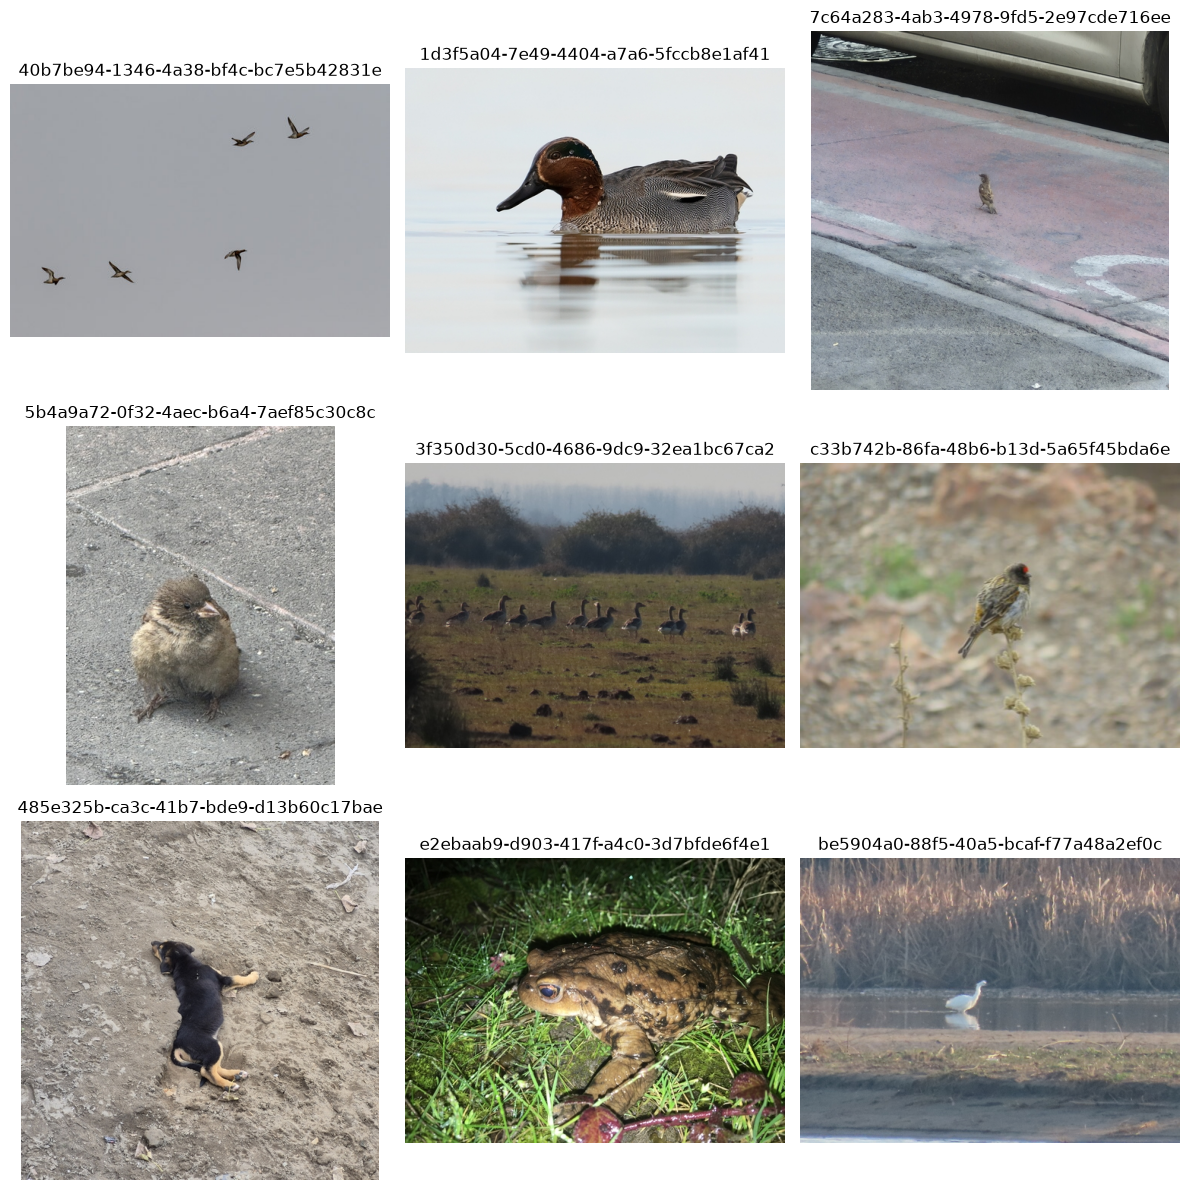

In [45]:
sample_images = (
    images_df[images_df["file_exists"]]
    .sample(min(9, images_df["file_exists"].sum()))
)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (_, row) in zip(axes.flat, sample_images.iterrows()):
    img = Image.open(row["resolved_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(str(row["image_id"]))
    ax.axis("off")

for ax in axes.flat[len(sample_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
device = get_device()

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

Selected device: cpu


بیمه حضرت ابولفضل میریم جلو

In [48]:
model, device = load_dinov2()

model.eval()

print("DINOv2 Small loaded successfully.")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to C:\Users\Lenovo/.cache\torch\hub\main.zip


C:\Users\Lenovo/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\Lenovo/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\Lenovo/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to C:\Users\Lenovo/.cache\torch\hub\checkpoints\dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [03:07<00:00, 471kB/s]


DINOv2 Small loaded successfully.


In [52]:
from dinov2_embeddings import build_transform

transform = build_transform()

sample_path = images_df.loc[
    images_df["file_exists"], "resolved_path"
].iloc[0]

image = Image.open(sample_path).convert("RGB")

input_tensor = transform(image).unsqueeze(0).to(device)

with torch.inference_mode():
    output = model(input_tensor)

print("Output shape:", output.shape)
print("Embedding dimension:", output.shape[-1])

Output shape: torch.Size([1, 384])
Embedding dimension: 384


In [53]:
valid_df = images_df[
    images_df["file_exists"]
].copy().reset_index(drop=True)

valid_df["image_path"] = (
    valid_df["resolved_path"].astype(str)
)

print("Images ready for embedding:", len(valid_df))

Images ready for embedding: 28132


In [54]:
BATCH_SIZE = 32
NUM_WORKERS = 0
NORMALIZE = True

print("Batch size:", BATCH_SIZE)
print("Device:", device)

Batch size: 32
Device: cpu


In [ ]:
embeddings = extract_embeddings(
    images_df=valid_df,
    model=model,
    device=device,
    base_dir=None,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    normalize=NORMALIZE,
    show_progress=True
)



Extracting DINOv2 embeddings: 100%|██████████| 880/880 [29:32<00:00,  2.01s/it]  


In [56]:
valid_embeddings = [
    x for x in embeddings
    if x is not None and len(x) == 384
]

failed_embeddings = len(embeddings) - len(valid_embeddings)

print("Total processed:", len(embeddings))
print("Successful:", len(valid_embeddings))
print("Failed:", failed_embeddings)

print("Embedding shape:",
      np.array(valid_embeddings).shape)

Total processed: 28132
Successful: 28132
Failed: 0
Embedding shape: (28132, 384)


In [57]:
embedding_matrix = np.array(
    valid_embeddings,
    dtype=np.float32
)

norms = np.linalg.norm(embedding_matrix, axis=1)

print("Mean norm:", norms.mean())
print("Min norm:", norms.min())
print("Max norm:", norms.max())

Mean norm: 1.0
Min norm: 0.9999998
Max norm: 1.0000001


In [58]:
embedded_df = save_embeddings_parquet(
    images_df=valid_df.drop(columns=["resolved_path", "file_exists"]),
    embeddings=embeddings,
    output_path=OUTPUT_PATH,
    column_name="embedding"
)

display(embedded_df.head())

,image_id,observation_uuid,image_path,animal_present,embedding
0,001cc818-ac3e-4750-979d-4d2d9d8358f7,001cc818-ac3e-4750-979d-4d2d9d8358f7,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,None,"[-0.04448, -0.025397, -0.149815, -0.006841, -0..."
1,0096e64b-71cf-42d9-b8ad-519bcacd14a8,0096e64b-71cf-42d9-b8ad-519bcacd14a8,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,None,"[-0.022113, -0.032662, -0.120739, -0.02755, -0..."
2,01057a20-6a12-4d43-8a0d-edaead5284e5,01057a20-6a12-4d43-8a0d-edaead5284e5,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,None,"[-0.018675, -0.094978, -0.006159, -0.050003, 0..."
3,014f362c-2e4e-4e51-aa4e-76b6d2315a32,014f362c-2e4e-4e51-aa4e-76b6d2315a32,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,None,"[0.027847, -0.063047, -0.045055, -0.014622, -0..."
4,0162c51c-4627-417c-b6f2-b75f3164ba69,0162c51c-4627-417c-b6f2-b75f3164ba69,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,None,"[-0.007697, -0.036371, 0.025362, -0.06874, -0...."


In [59]:
saved_df = pd.read_parquet(OUTPUT_PATH)

print("Output path:", OUTPUT_PATH)
print("Dataset shape:", saved_df.shape)

print("\nColumns:")
print(saved_df.columns.tolist())

print("\nEmbedding dimension:",
      len(saved_df["embedding"].dropna().iloc[0]))

Output path: d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\data\embeddings\images_dinov2.parquet
Dataset shape: (28132, 5)

Columns:
['image_id', 'observation_uuid', 'image_path', 'animal_present', 'embedding']

Embedding dimension: 384


In [60]:
embedding_matrix = np.stack(
    saved_df["embedding"].values
).astype(np.float32)

print("Embedding matrix:", embedding_matrix.shape)

Embedding matrix: (28132, 384)


In [61]:
query_idx = 0

similarities = (
    embedding_matrix @ embedding_matrix[query_idx]
)

similar_indices = np.argsort(
    similarities
)[::-1][1:11]

similarity_df = saved_df.iloc[similar_indices].copy()

similarity_df["similarity"] = (
    similarities[similar_indices]
)

display(
    similarity_df[
        ["image_id", "image_path", "similarity"]
    ]
)

,image_id,image_path,similarity
40,067db68f-b729-40ed-8d26-22991655c500,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.615109
1124,afc305d7-6281-40f3-859d-8e54abe5de2a,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.587186
1202,bd50d527-fa74-4bcf-bfb4-85e6037502a5,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.566806
740,73665f37-e7e9-4801-a488-b2337351cd8c,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.564052
742,73b78695-d8a4-48b5-acf4-2c5302901479,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.560025
1001,9d131936-9c36-4675-96c7-645e72c0b001,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.556257
647,65511b6a-bf57-483c-8a15-f6539e28755e,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.549369
56,08acf713-b912-4203-93d3-74b20f22f54f,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.542214
98,1018ce19-300a-46a3-bce0-961098137abf,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.539543
1288,caba6f0c-a5ec-4217-ab8d-69913e134399,d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2...,0.538405


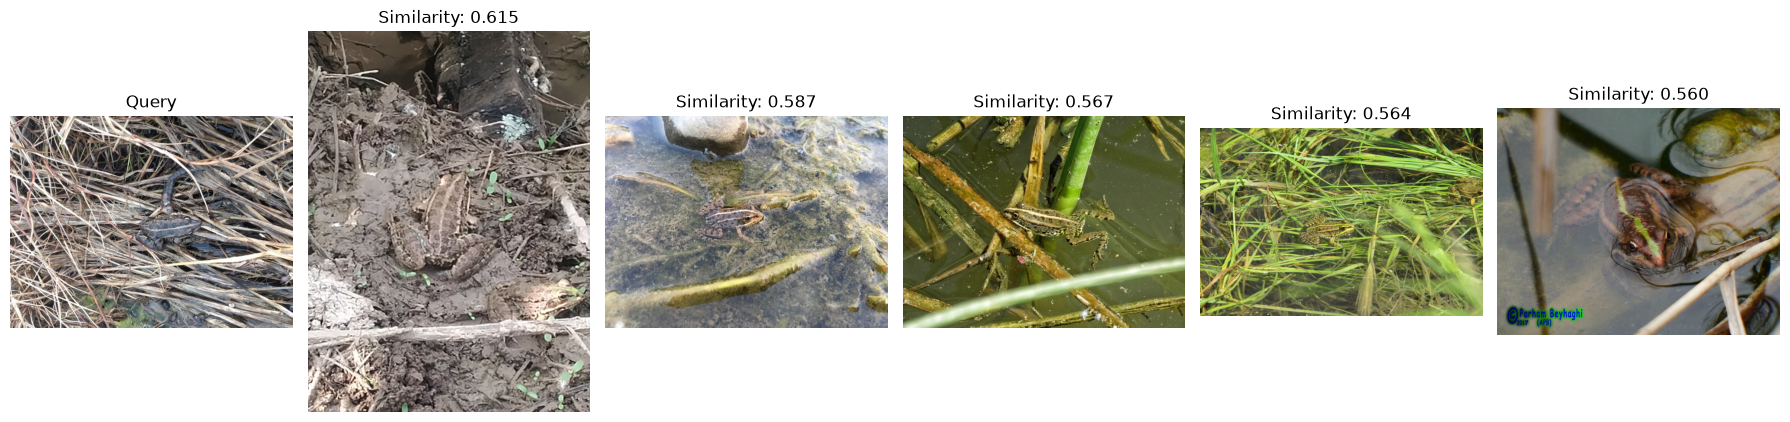

In [62]:
query_image = Image.open(
    saved_df.iloc[query_idx]["image_path"]
).convert("RGB")

fig, axes = plt.subplots(1, 6, figsize=(18, 5))

axes[0].imshow(query_image)
axes[0].set_title("Query")
axes[0].axis("off")

for ax, idx in zip(axes[1:], similar_indices[:5]):
    row = saved_df.iloc[idx]

    img = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(f"Similarity: {similarities[idx]:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
report = {
    "Total images": len(images_df),
    "Images with valid paths": int(images_df["file_exists"].sum()),
    "Images embedded": len(valid_embeddings),
    "Failed embeddings": failed_embeddings,
    "Embedding dimension": 384,
    "Model": "DINOv2 Small ViT-S/14",
    "Normalized": NORMALIZE,
}

for key, value in report.items():
    print(f"{key}: {value}")

Total images: 28132
Images with valid paths: 28132
Images embedded: 28132
Failed embeddings: 0
Embedding dimension: 384
Model: DINOv2 Small ViT-S/14
Normalized: True


In [64]:
import json

report_path = EMBEDDINGS_DIR / "embedding_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=4)

print("Report saved:", report_path)

Report saved: d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\data\embeddings\embedding_report.json
